# When can myopic and Bayes-optimal exploration be told apart?

**An identifiability study with `tinybamdp`.**

> **Research question.** Zhang & Yu (2013) found that human bandit choices are better described by a *myopic* Knowledge-Gradient
> (KG) policy than by the Bayes-optimal policy (OPT). Under what task designs can these two models be distinguished from choice
> data at all, and which of their parameters are identifiable?

The models, planners and fitting tools are introduced in the companion notebook **`tinybamdp_tutorial.ipynb`**. This notebook runs
the validation study interactively (§ 1) and reports the full-size reference results (§ 2), whose figures are embedded and display
without running anything.

| § | Section | What you can do |
|---|---|---|
| 0 | Setup | load the library and the study code from the repository |
| 1 | Validation study | equivalence check, tie-aware recovery with CIs, horizon sweep, likelihood surface, CV, mixed horizons, design heat map |
| 2 | Findings & limitations | reference results, figures, power table, take-aways, references |

## 0 · Setup
Run this cell first. It finds the repository and makes `tinybamdp` (the library) and `study` importable, without copying any code:

1. **Local Jupyter**: open the notebook from the repository's `notebook/` folder; nothing else to do.
2. **Colab** (default): the cell clones [bunytwirls/tinybamdp-library](https://github.com/bunytwirls/tinybamdp-library) automatically.
3. **Offline / no GitHub access**: set `REPO_URL = ""` and upload `tinybamdp.zip` (the repository) when asked.

In [ ]:
REPO_URL = "https://github.com/bunytwirls/tinybamdp-library.git"   # set to "" to use tinybamdp.zip instead
import os, sys, pathlib, subprocess, zipfile
try:                   # Colab: enable interactive widgets (no-op elsewhere)
    from google.colab import output
    output.enable_custom_widget_manager()
except Exception:
    pass
def _find_repo():
    for cand in (pathlib.Path.cwd().parent, pathlib.Path.cwd(), pathlib.Path("tinybamdp_repo")):
        if (cand / "tinybamdp" / "__init__.py").exists() and (cand / "study").exists():
            return cand.resolve()
    target = pathlib.Path("tinybamdp_repo")
    if REPO_URL:
        r = subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(target)], capture_output=True, text=True)
        if r.returncode == 0:
            return target.resolve()
        print("could not clone", REPO_URL, "- falling back to tinybamdp.zip:", r.stderr.strip()[:200])
    zp = pathlib.Path("tinybamdp.zip")
    if not zp.exists():
        try:
            from google.colab import files
            zp = pathlib.Path(next(iter(files.upload())))
        except ImportError:
            raise FileNotFoundError("Open this notebook from the repository, put tinybamdp.zip next to it, or set REPO_URL.")
    zipfile.ZipFile(zp).extractall(target)
    return target.resolve()
REPO = _find_repo()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print("repository:", REPO)

### Shared imports and UI helpers

In [ ]:
import importlib, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as W
from IPython.display import display, HTML, clear_output
import tinybamdp
for m in list(sys.modules):
    if m.startswith("tinybamdp"): importlib.reload(sys.modules[m])
from tinybamdp import (bandit_dp, bamdp, beliefs, fitting, models, pomdp, task,
                       get_model, simulate, sample_task, log_likelihood)
import study
for m in list(sys.modules):
    if m.startswith("study"): importlib.reload(sys.modules[m])
from study import analysis, plots
plots.style()
fitting.MP_CONTEXT = "spawn"     # forking a running Jupyter kernel can deadlock; spawn is safe
C = plots.COLORS
AUTORUN = os.environ.get("TB_AUTORUN") == "1"     # used for headless testing only

_CSS = '''<style>
.tb-scroll{max-height:300px;overflow:auto;border:1px solid #d9d8d3;border-radius:6px;background:#fff}
.tb-scroll table{border-collapse:collapse;font-size:12.5px;color:#0b0b0b;width:100%}
.tb-scroll th{position:sticky;top:0;background:#fdeef5;color:#0b0b0b;padding:5px 9px;text-align:right}
.tb-scroll td{padding:4px 9px;border-bottom:1px solid #eeede9;text-align:right}
.tb-scroll tr:hover td{background:#fdf5f9}
.tb-card{background:#fdf0f6;color:#0b0b0b;border-left:4px solid #DC267F;padding:8px 12px;border-radius:4px;margin:6px 0;font-size:13px}
.tb-warn{border-left-color:#FE6100;background:#fff4ec}
</style>'''
def table(df, height=300, index=True, fmt="{:.3f}"):
    html = df.to_html(index=index, float_format=lambda x: fmt.format(x), border=0)
    return HTML(_CSS + f'<div class="tb-scroll" style="max-height:{height}px">{html}</div>')
def card(text, warn=False):
    return HTML(_CSS + f'<div class="tb-card {"tb-warn" if warn else ""}">{text}</div>')
def outbox(h=None):
    lay = W.Layout(border="1px solid #e4e3df", padding="4px", overflow="auto")
    if h: lay.max_height = f"{h}px"
    return W.Output(layout=lay)
def button(desc, style="primary", icon=""):
    return W.Button(description=desc, button_style=style, icon=icon, layout=W.Layout(width="auto"))
SL = dict(continuous_update=False, style={"description_width": "110px"}, layout=W.Layout(width="330px"))
print("tinybamdp", tinybamdp.__version__)

## 1 · Validation study
We follow Wilson & Collins (2019): simulate subjects from each model with parameters drawn from a behaviourally sensible range,
fit every model, then check **parameter recovery** (true vs fitted) and **model recovery**.

Model recovery here is **tie-aware** and reports **evidence strength**:
* if the best and second-best models are within 0.1 BIC, the subject counts as a *tie* rather than being assigned by `argmin`'s
  tie-breaking;
* next to accuracy we show 95% Wilson confidence intervals and the share of subjects with $|\Delta\mathrm{BIC}|>2$ (positive) and $>6$
  (strong evidence);
* the **inversion matrix** $P(\text{generating}\mid\text{best fit})$ answers the question you actually face with real data: *if
  model X wins, how likely is it that X generated the data?*

The research question is answered by a **horizon sweep** at a fixed budget of 240 choices per subject (games of length $T$,
$G = 240/T$ games). The cell below first establishes *where KG and OPT are identical*, which is where no amount of data can
separate them. Two facts explain the pattern: (i) with at most two choices left, KG's one-step lookahead is exact for **any**
posteriors; (ii) on the first trial of a game all arms share the prior, so both policies are indifferent. In a T-trial game
only trials 2 … T−2 can tell the models apart, at most a fraction (T−3)/T of the data; it is zero for T ≤ 3.

In [ ]:
# Where are KG and OPT behaviourally identical?  Max |gap_OPT - gap_KG| over all hyperstates and arms,
# maximised over random Beta priors (log-uniform on [0.1, 10]).  0 = identical choice probabilities for every tau.
eq_n = W.IntSlider(value=30, min=10, max=300, step=10, description="random priors", **SL)
eq_b = button("Re-run equivalence check", "primary", "refresh")
eq_out = outbox(260)
def run_equiv(_=None):
    with eq_out:
        clear_output(wait=True)
        t0 = time.perf_counter()
        tab = analysis.equivalence_table((2, 3, 4), (2, 3, 4, 5), n_priors=eq_n.value)
        het = analysis.equivalence_table_hetero((2, 3), (2, 3, 4), n_priors=max(10, eq_n.value // 3))
        df = pd.DataFrame([{"arms K": K, "T": T, "max diff": v} for (K, T), v in tab.items()]
                          ).pivot(index="arms K", columns="T", values="max diff")
        dh = pd.DataFrame([{"arms K": K, "choices left": T, "max diff": v} for (K, T), v in het.items()]
                          ).pivot(index="arms K", columns="choices left", values="max diff")
        display(card(f"<b>Shared prior</b> (all arms start equal): max difference in value gaps over all hyperstates and "
                     f"{eq_n.value} priors. Values ~1e-16 are floating-point zero."))
        display(table(df, height=170, fmt="{:.1e}"))
        display(card("<b>Per-arm priors</b> (equivalently, any posteriors) with this many choices left: exact only with ≤ 2 "
                     f"left. So the shared-prior T = 3 equality is a consequence of symmetry, not a deeper result · "
                     f"{time.perf_counter() - t0:.1f} s", warn=True))
        display(table(dh, height=140, fmt="{:.1e}"))
eq_b.on_click(run_equiv)
display(W.HBox([eq_n, eq_b]), eq_out); run_equiv()

In [ ]:
TIE_EPS = 0.1
ALL = list(models.MODELS)
Nw = W.IntSlider(value=20, min=5, max=150, step=5, description="subjects/model", **SL)
Jw = W.IntSlider(value=min(2, os.cpu_count() or 1), min=1, max=os.cpu_count() or 2, description="CPU workers", **SL)
Tw = W.IntSlider(value=10, min=3, max=30, description="T (baseline)", **SL)
Kw = W.IntSlider(value=2, min=2, max=4, description="arms K", **SL)
Bw = W.IntSlider(value=240, min=60, max=600, step=30, description="choices/subject", **SL)
Sw = W.IntSlider(value=3, min=1, max=8, description="restarts", **SL)
EAw = W.FloatSlider(value=2.0, min=0.5, max=5, step=0.5, description="env prior a", **SL)
EBw = W.FloatSlider(value=2.0, min=0.5, max=5, step=0.5, description="env prior b", **SL)
Mw = W.SelectMultiple(options=ALL, value=tuple(ALL), description="models", layout=W.Layout(width="230px", height="110px"))
Hw = W.SelectMultiple(options=[2, 3, 5, 8, 12, 20, 30], value=(2, 5, 12, 30), description="sweep T",
                      layout=W.Layout(width="200px", height="110px"))
prog = W.IntProgress(min=0, max=1, description="progress", bar_style="info", layout=W.Layout(width="420px"))
def _p(done, total): prog.max = total; prog.value = done
def _env(): return (EAw.value, EBw.value)
def _too_big(K, T, names):
    return "OPT" in names and K == 4 and T > 15
b1 = button("1 · Parameter + model recovery", "primary", "play")
b2 = button("2 · Horizon sweep (KG vs OPT)", "primary", "play")
b3 = button("3 · Likelihood surface", "primary", "play")
b4 = button("4 · Cross-validation vs BIC", "primary", "play")
b5 = button("5 · Mixed-horizon design", "primary", "play")
b6 = button("6 · Design heat map (K × T)", "success", "th")
o1, o2, o3, o4, o5, o6 = outbox(), outbox(), outbox(), outbox(), outbox(), outbox()

def summary_frame(res, names):
    S = fitting.recovery_summary(res, names, tie_eps=TIE_EPS)
    df = pd.DataFrame(S).T[["n", "acc", "acc_lo", "acc_hi", "tie", "decisive>2", "decisive>6", "acc|decisive>2", "median_margin"]]
    return df.rename(columns={"acc_lo": "95% CI lo", "acc_hi": "95% CI hi", "median_margin": "median ΔBIC to runner-up"})

def run_recovery(_=None):
    names = list(Mw.value); K, T = Kw.value, Tw.value
    with o1:
        clear_output(wait=True)
        if _too_big(K, T, names):
            display(card("OPT with 4 arms is limited to T ≤ 15.", warn=True)); return
        G = max(1, Bw.value // T); t0 = time.perf_counter()
        res = fitting.run_recovery(names, names, Nw.value, G, T, K=K, n_starts=Sw.value, seed=1,
                                   n_jobs=Jw.value, progress=_p, env_prior=_env())
        M = fitting.confusion_matrix(res, names, tie_eps=TIE_EPS)
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
        plots.confusion(axes[0], M, names, title=f"P(best fit | generating)  K={K}, T={T}, G={G}")
        plots.confusion(axes[1], fitting.inversion_matrix(M), names, title="P(generating | best fit)")
        fig.tight_layout(); plt.show()
        display(card(f"Tie-aware recovery · {Nw.value} subjects/model · fit failures: {100 * fitting.failure_rate(res):.1f}% "
                     f"· {time.perf_counter() - t0:.0f} s"))
        display(table(summary_frame(res, names), height=220))
        n_par = sum(get_model(m).n_params for m in names); cols = 4; rows = int(np.ceil(n_par / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(10, 2.3 * rows)); axes = np.atleast_1d(axes).ravel(); k = 0
        stats = {}
        for mname in names:
            for pname, (tr, rc) in fitting.param_table(res, mname).items():
                plots.recovery_scatter(axes[k], tr, rc, f"{mname}:{pname}", C[mname], log=pname in ("n", "tau"))
                axes[k].set_xlabel(""); axes[k].set_ylabel(""); k += 1
            for pname, v in fitting.recovery_stats(res, mname).items():
                stats[f"{mname}.{pname}"] = v
        for ax in axes[k:]: ax.axis("off")
        fig.tight_layout(); plt.show()
        display(card("Parameter recovery (log scale for n, τ). Bias = median(recovered − true)."))
        display(table(pd.DataFrame(stats).T, height=260))
        corr = {}
        for mname in [m for m in ("KG", "KG-DBM", "OPT") if m in names]:
            tab = fitting.param_table(res, mname)
            e = {p: (np.log(v[1]) - np.log(v[0])) if p in ("n", "tau") else v[1] - v[0] for p, v in tab.items()}
            corr[mname] = {"corr(err n, err τ)": np.corrcoef(e["n"], e["tau"])[0, 1],
                           "corr(err m, err τ)": np.corrcoef(e["m"], e["tau"])[0, 1]}
        if corr:
            display(card("Correlation of estimation errors across subjects. A large positive value means the two parameters trade off."))
            display(table(pd.DataFrame(corr).T, height=140))

def run_sweep(_=None):
    K = Kw.value
    with o2:
        clear_output(wait=True)
        Hs = sorted(Hw.value)
        if K == 4: Hs = [T for T in Hs if T <= 15]
        rows, dis = {}, {}
        for T in Hs:
            r = fitting.run_recovery(["KG", "OPT"], ["KG", "OPT"], Nw.value, max(1, Bw.value // T), T, K=K, n_starts=Sw.value,
                                     seed=100 + T, n_jobs=Jw.value, progress=_p, env_prior=_env())
            S = fitting.recovery_summary(r, ["KG", "OPT"], tie_eps=TIE_EPS)
            rows[T] = {"P(KG|KG)": S["KG"]["acc"], "KG lo": S["KG"]["acc_lo"], "KG hi": S["KG"]["acc_hi"],
                       "P(OPT|OPT)": S["OPT"]["acc"], "OPT lo": S["OPT"]["acc_lo"], "OPT hi": S["OPT"]["acc_hi"],
                       "tie": (S["KG"]["tie"] + S["OPT"]["tie"]) / 2,
                       "|ΔBIC|>2": (S["KG"]["decisive>2"] + S["OPT"]["decisive>2"]) / 2,
                       "|ΔBIC|>6": (S["KG"]["decisive>6"] + S["OPT"]["decisive>6"]) / 2}
            dis[T] = 100 * analysis.policy_disagreement(T, K=K, G=1000, env_prior=_env()).mean()
        df = pd.DataFrame(rows).T; df["% argmax disagreement"] = pd.Series(dis)
        fig, axes = plt.subplots(1, 3, figsize=(11, 3))
        for g, mk in [("KG", "o"), ("OPT", "s")]:
            y = df[f"P({g}|{g})"]
            axes[0].errorbar(Hs, y, yerr=[y - df[f"{g} lo"], df[f"{g} hi"] - y], fmt=mk + "-", capsize=3, color=C[g], label=f"{g}→{g}")
        axes[0].plot(Hs, df["tie"], "^:", color=plots.MUTED, label="tie"); axes[0].set_ylim(0, 1.02); axes[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
        axes[0].set_title(f"Recovery, {Bw.value} choices (95% CI)")
        axes[1].plot(Hs, df["|ΔBIC|>2"], "o-", color=plots.INK, label=">2"); axes[1].plot(Hs, df["|ΔBIC|>6"], "s--", color=plots.MUTED, label=">6")
        axes[1].set_ylim(0, 1.02); axes[1].legend(fontsize=7); axes[1].set_title("Share with decisive evidence")
        axes[2].plot(Hs, df["% argmax disagreement"], "o-", color=plots.INK); axes[2].set_title("KG vs OPT disagreement (%)")
        for ax in axes: ax.set_xscale("log"); ax.set_xticks(Hs, Hs); ax.minorticks_off(); ax.set_xlabel("horizon T")
        fig.tight_layout(); plt.show()
        display(table(df, height=240))

def run_surface(_=None):
    with o3:
        clear_output(wait=True)
        rng = np.random.default_rng(11); true = {"m": .5, "n": 4.0, "tau": 5.0}
        d = simulate(get_model("OPT"), true, sample_task(max(1, Bw.value // Tw.value), 2, rng, *_env()), Tw.value, rng)
        xs, ys = np.geomspace(.5, 20, 30), np.geomspace(.5, 50, 30)
        Z = analysis.likelihood_surface("OPT", d, {"m": .5}, "n", xs, "tau", ys)
        i, j = np.unravel_index(Z.argmax(), Z.shape)
        fig, ax = plt.subplots(figsize=(4.8, 3.6))
        cs = plots.surface(ax, xs, ys, Z, "prior strength n", "softmax precision τ", truth=(4, 5), mle=(xs[j], ys[i]))
        fig.colorbar(cs, ax=ax, label="log-lik − max"); ax.set_title("OPT log-likelihood, m fixed (white line: 95% region)")
        plt.tight_layout(); plt.show()

def run_cv(_=None):
    names = list(Mw.value); K, T = Kw.value, Tw.value
    with o4:
        clear_output(wait=True)
        if _too_big(K, T, names):
            display(card("OPT with 4 arms is limited to T ≤ 15.", warn=True)); return
        t0 = time.perf_counter(); G = max(2, Bw.value // T)
        res = fitting.run_recovery(names, names, max(3, Nw.value // 3), G, T, K=K, n_starts=Sw.value, seed=600,
                                   n_jobs=Jw.value, progress=_p, env_prior=_env(), cv=True)
        Mb = fitting.confusion_matrix(res, names, "bic", tie_eps=TIE_EPS)
        Mc = fitting.confusion_matrix(res, names, "cv_nll", tie_eps=TIE_EPS / 2)
        agree = np.mean([fitting.classify(f, names, "bic", TIE_EPS)[0] == fitting.classify(f, names, "cv_nll", TIE_EPS / 2)[0]
                         for _, _, f in res])
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
        plots.confusion(axes[0], Mb, names, title="BIC")
        plots.confusion(axes[1], Mc, names, title="Leave-one-game-out CV", xlabel="best model (held-out NLL)")
        fig.tight_layout(); plt.show()
        display(card(f"{max(3, Nw.value // 3)} subjects/model (CV costs ≈ G extra warm-started fits per model) · "
                     f"BIC and CV pick the same model for <b>{100 * agree:.0f}%</b> of subjects · {time.perf_counter() - t0:.0f} s"))

def run_mixed(_=None):
    with o5:
        clear_output(wait=True)
        B = Bw.value
        designs = {"fixed T=5": [(B // 5, 5)], "fixed T=20": [(B // 20, 20)], "mixed 5 + 20": [(B // 10, 5), (B // 40, 20)]}
        opt = get_model("OPT"); rng = np.random.default_rng(700); rows = {}
        total = len(designs) * Nw.value; done = 0
        for name, des in designs.items():
            e_n, e_t = [], []
            for _ in range(Nw.value):
                tr = opt.sample_params(rng)
                f = fitting.fit("OPT", task.simulate_design(opt, tr, des, 2, rng, _env()), Sw.value, rng)
                e_n.append(np.log(f.params["n"] / tr["n"])); e_t.append(np.log(f.params["tau"] / tr["tau"]))
                done += 1; _p(done, total)
            rows[name] = {"corr(err n, err τ)": np.corrcoef(e_n, e_t)[0, 1],
                          "RMSE log n": np.sqrt(np.mean(np.square(e_n))), "RMSE log τ": np.sqrt(np.mean(np.square(e_t)))}
        df = pd.DataFrame(rows).T
        fig, ax = plt.subplots(figsize=(6, 2.2))
        ax.barh(df.index, df["corr(err n, err τ)"], color=C["OPT"], height=0.5); ax.set_xlim(0, 1); ax.invert_yaxis()
        ax.set_xlabel("corr(err n, err τ)"); ax.set_title("Does mixing horizons break the trade-off?"); plt.tight_layout(); plt.show()
        display(table(df, height=150))

def run_design(_=None):
    with o6:
        clear_output(wait=True)
        Ks, Ts = [2, 3, 4], [4, 8, 15]
        acc = np.zeros((len(Ks), len(Ts))); dec = np.zeros_like(acc); t0 = time.perf_counter()
        for i, K in enumerate(Ks):
            for j, T in enumerate(Ts):
                r = fitting.run_recovery(["KG", "OPT"], ["KG", "OPT"], max(4, Nw.value // 2), max(1, Bw.value // T), T, K=K,
                                         n_starts=Sw.value, seed=900 + 10 * K + T, n_jobs=Jw.value, progress=_p, env_prior=_env())
                S_ = fitting.recovery_summary(r, ["KG", "OPT"], tie_eps=TIE_EPS)
                acc[i, j] = np.mean([v["acc"] for v in S_.values()]); dec[i, j] = np.mean([v["decisive>2"] for v in S_.values()])
        fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
        for ax, M, title in [(axes[0], acc, "KG vs OPT accuracy"), (axes[1], dec, "share with |ΔBIC| > 2")]:
            ax.imshow(M, cmap=plots.SEQ, vmin=0, vmax=1, aspect="auto"); ax.grid(False)
            ax.set_xticks(range(len(Ts)), Ts); ax.set_yticks(range(len(Ks)), Ks); ax.set_xlabel("trials per game T"); ax.set_ylabel("arms K")
            for a_ in range(len(Ks)):
                for b_ in range(len(Ts)):
                    ax.text(b_, a_, f"{M[a_, b_]:.2f}", ha="center", va="center", color="white" if M[a_, b_] > .55 else plots.INK)
            ax.set_title(title)
        fig.tight_layout(); plt.show()
        display(card(f"{max(4, Nw.value // 2)} subjects per model per cell, {Bw.value} choices each · {time.perf_counter() - t0:.0f} s. "
                     "§ 2 shows the full-size version (60 per cell, five horizons)."))

b1.on_click(run_recovery); b2.on_click(run_sweep); b3.on_click(run_surface); b4.on_click(run_cv); b5.on_click(run_mixed)
b6.on_click(run_design)
display(card("Settings apply to all six analyses. Defaults are sized for a few minutes each on Colab; § 2 shows the full-size reference run."),
        W.HBox([W.VBox([Nw, Jw, Sw, Bw]), W.VBox([Tw, Kw, EAw, EBw]), Mw, Hw]), prog,
        W.HBox([b1, b2, b3]), W.HBox([b4, b5, b6]), o1, o2, o3, o4, o5, o6)
if AUTORUN:
    Nw.value = 4; Sw.value = 2; Mw.value = ("RW", "KG", "KG-DBM", "OPT"); run_recovery()
    Hw.value = (2, 12); run_sweep(); run_surface(); Nw.value = 6; run_cv(); Nw.value = 6; run_mixed(); Nw.value = 4; run_design()

## 2 · Findings and limitations

Reference run (`python study/run_all.py`): 100 simulated subjects per model, 240 choices each,
tie threshold |ΔBIC| < 0.1. The figures below are embedded in the notebook, so they display without running anything.

**Sanity check.** An OPT agent with prior Beta(2, 2) (400 games) is fitted back as Beta(2.11, 2.27).
Zhang & Yu (2013) report a similar check, recovering Beta(1.93, 2.15).

### 2.1 Headline: which designs can separate myopic from optimal exploration?
KG-vs-OPT recovery at a fixed budget of 240 choices, for 2–4 arms and 4–15 trials per game (60 subjects per model
per cell). Use this as a design guideline: aim for cells with a high share of decisive evidence (right panel), not just high
accuracy.

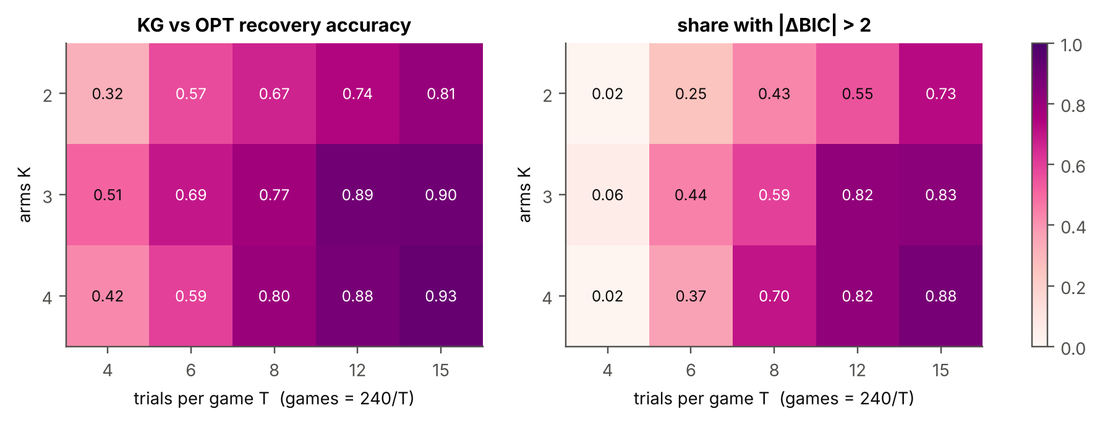

### 2.2 Horizon sweep in detail (KG vs OPT, 2 arms)

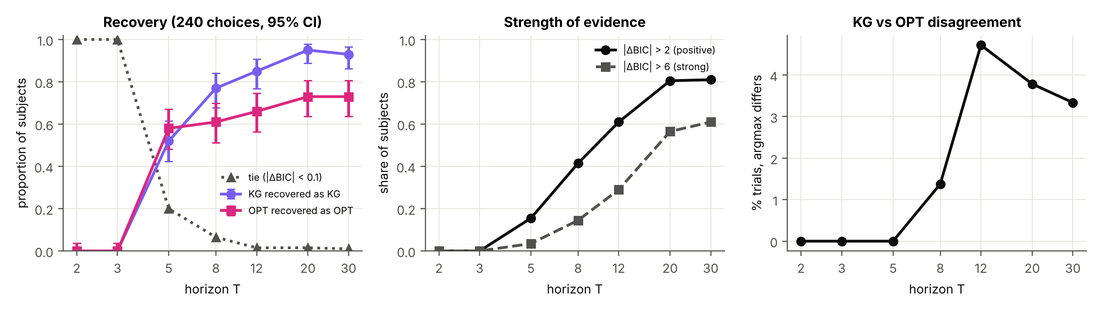

| T | games | P(KG→KG) [95% CI] | P(OPT→OPT) [95% CI] | tie | \|ΔBIC\|>2 | \|ΔBIC\|>6 | informative trials (T−3)/T | % argmax disagreement |
|---|---|---|---|---|---|---|---|---|
| 2 | 120 | 0.00 [0.00, 0.04] | 0.00 [0.00, 0.04] | 1.00 | 0.00 | 0.00 | 0% | 0.0 |
| 3 | 80 | 0.00 [0.00, 0.04] | 0.00 [0.00, 0.04] | 1.00 | 0.00 | 0.00 | 0% | 0.0 |
| 5 | 48 | 0.52 [0.42, 0.62] | 0.58 [0.48, 0.67] | 0.20 | 0.16 | 0.04 | 40% | 0.0 |
| 8 | 30 | 0.77 [0.68, 0.84] | 0.61 [0.51, 0.70] | 0.07 | 0.41 | 0.15 | 62% | 1.4 |
| 12 | 20 | 0.85 [0.77, 0.91] | 0.66 [0.56, 0.75] | 0.01 | 0.61 | 0.29 | 75% | 4.7 |
| 20 | 12 | 0.95 [0.89, 0.98] | 0.73 [0.64, 0.81] | 0.01 | 0.80 | 0.56 | 85% | 3.8 |
| 30 | 8 | 0.93 [0.86, 0.97] | 0.73 [0.64, 0.81] | 0.01 | 0.81 | 0.61 | 90% | 3.3 |

**Where the models are identical.** Max difference between KG's and OPT's value gaps over all hyperstates and 200 random priors
(about 1e-16 is floating-point zero):

| arms K | T=2 | T=3 | T=4 | T=5 |
|---|---|---|---|---|
| 2 | 2e-16 | 6e-16 | 3e-02 | 1e-01 |
| 3 | 2e-16 | 6e-16 | 2e-01 | 4e-01 |
| 4 | 2e-16 | 6e-16 | 1e-01 | 3e-01 |

The same check with a **separate prior per arm** (equivalently, any posteriors) and this many choices left shows that KG is exact
only with ≤ 2 choices left. The shared-prior equality at T = 3 holds only because the first trial is symmetric:

| arms K | 2 left | 3 left | 4 left |
|---|---|---|---|
| 2 | 3e-16 | 1e-01 | 2e-01 |
| 3 | 4e-16 | 2e-01 | 4e-01 |

### 2.3 Model recovery at T = 10 (2 arms) and in Zhang & Yu's regime (4 arms, 15 trials, 20 games)

**2 arms, T = 10**: left, P(best fit | generating) with a tie column; right, the inversion P(generating | best fit).

| gen \ fit | RW | WSLS | KG | KG-DBM | OPT | tie |
|---|---|---|---|---|---|---|
| **RW** | 0.93 | 0.05 | 0.01 | 0.00 | 0.00 | 0.01 |
| **WSLS** | 0.00 | 1.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| **KG** | 0.37 | 0.01 | 0.54 | 0.01 | 0.06 | 0.01 |
| **KG-DBM** | 0.39 | 0.16 | 0.09 | 0.34 | 0.01 | 0.01 |
| **OPT** | 0.53 | 0.03 | 0.15 | 0.00 | 0.28 | 0.01 |

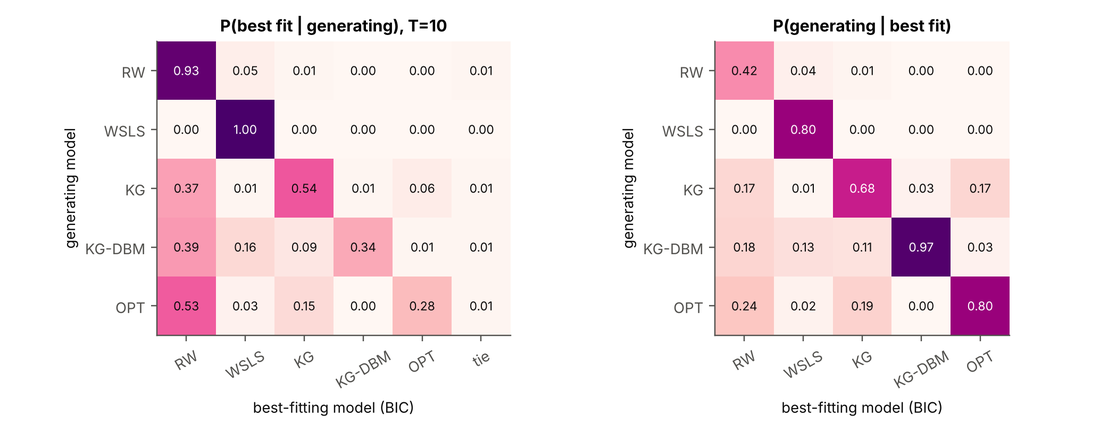

**4 arms, T = 15, 20 games** (N = 100 per model; KG vs OPT argmax disagreement 1.5% of trials):

| gen \ fit | RW | WSLS | KG | KG-DBM | OPT | tie |
|---|---|---|---|---|---|---|
| **RW** | 0.93 | 0.06 | 0.00 | 0.00 | 0.01 | 0.00 |
| **WSLS** | 0.00 | 1.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| **KG** | 0.02 | 0.00 | 0.96 | 0.00 | 0.01 | 0.01 |
| **KG-DBM** | 0.03 | 0.05 | 0.09 | 0.80 | 0.02 | 0.01 |
| **OPT** | 0.28 | 0.00 | 0.04 | 0.00 | 0.68 | 0.00 |

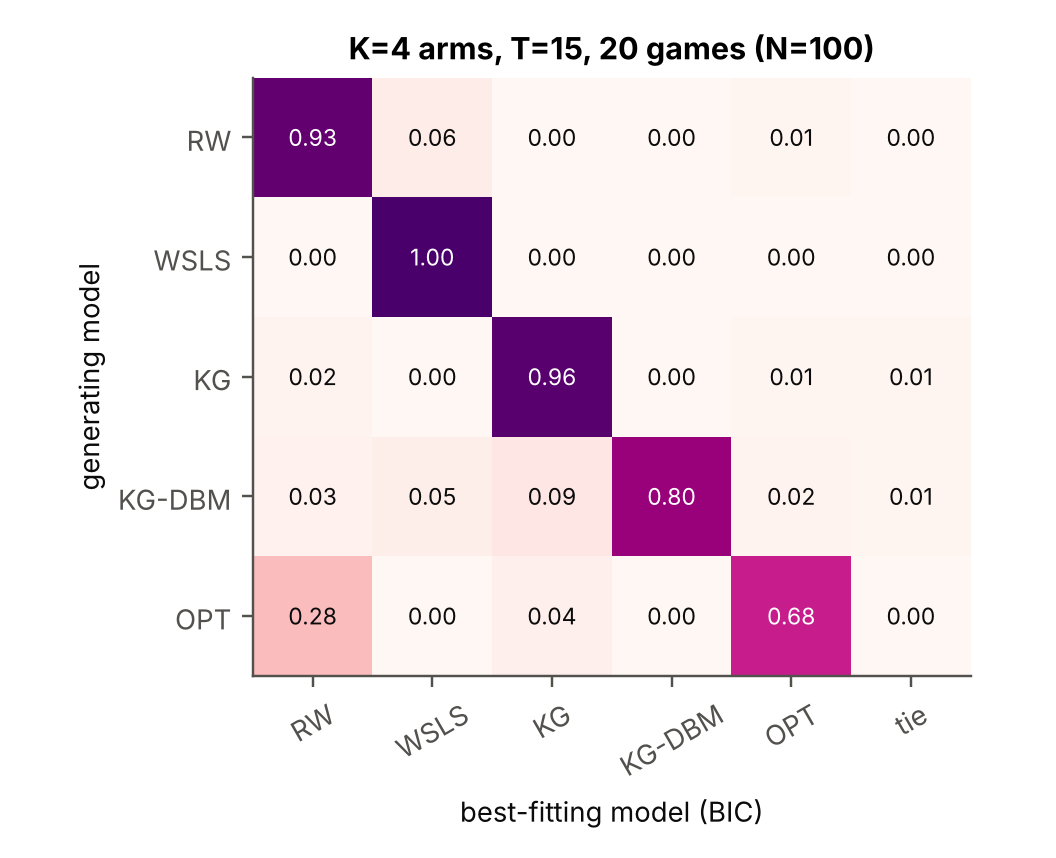

### 2.4 Cross-validation versus BIC (N = 100 per model, T = 10)
Leave-one-game-out held-out NLL picks the same model as BIC for **62%** of subjects; mean diagonal
accuracy BIC 0.66 vs CV 0.61.

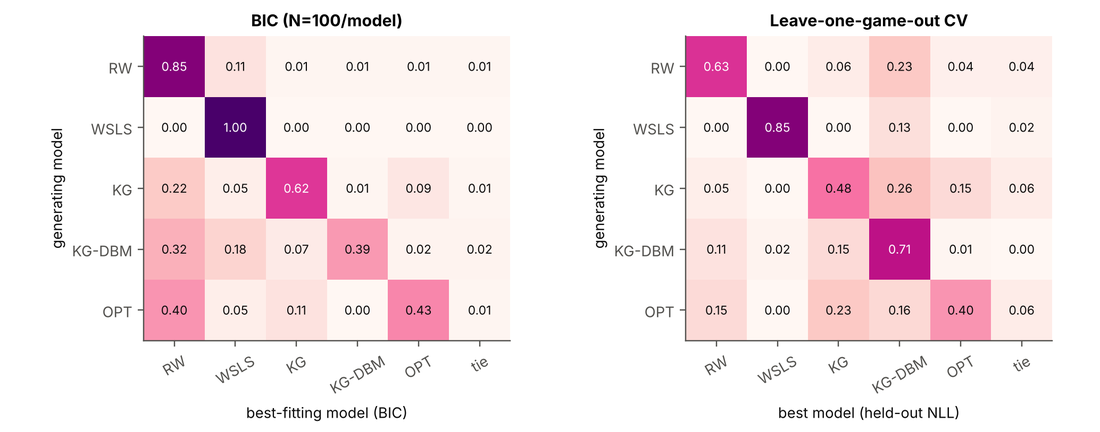

### 2.5 The prior-strength / noise trade-off, and whether mixing horizons breaks it
Error correlation corr(err n, err τ) at T = 10: KG 0.93, KG-DBM 0.92,
OPT 0.94. The prior mean m trades off much less (OPT 0.04).

| design (OPT, 240 choices) | corr(err n, err τ) | RMSE log n | RMSE log τ | r(true n, fitted n) |
|---|---|---|---|---|
| fixed T=5 | 0.93 | 1.76 | 1.27 | 0.32 |
| fixed T=20 | 0.95 | 0.96 | 0.66 | 0.66 |
| mixed 5 + 20 | 0.93 | 1.15 | 0.77 | 0.62 |

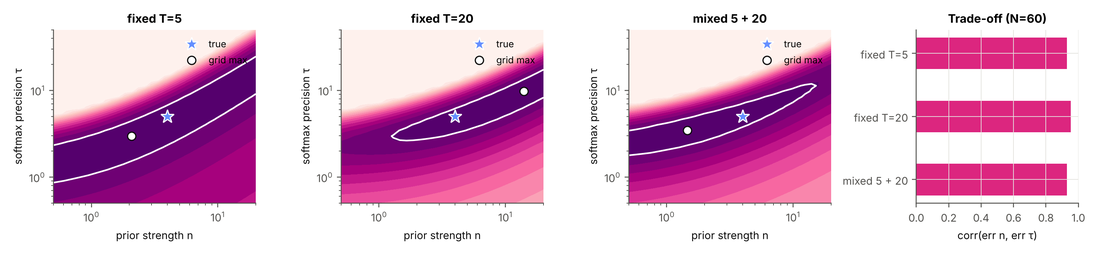

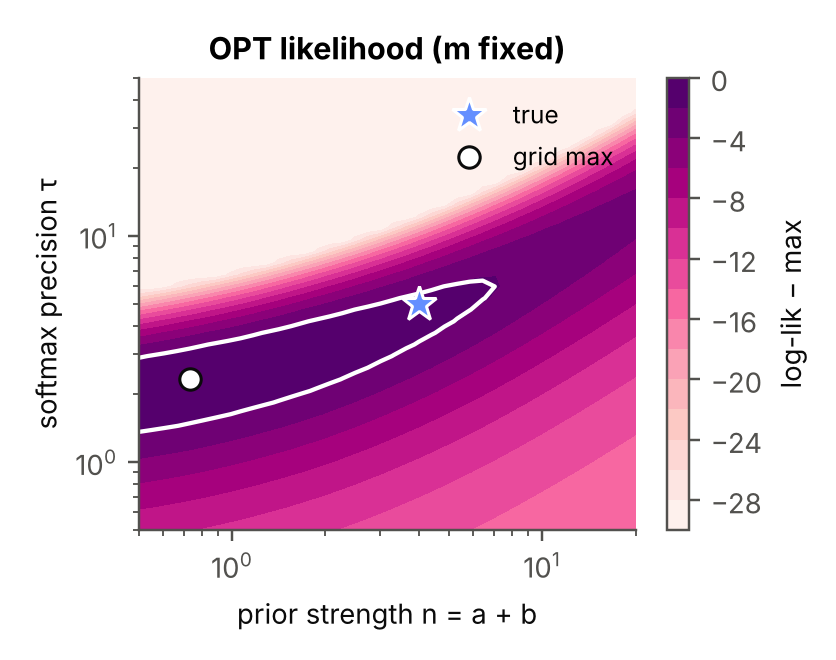

### 2.6 Parameter recovery (Pearson r; log scale for n, τ)
RW: eta 0.83, tau 0.72 · WSLS: eps 0.94 · KG: m 0.68, n 0.51, tau 0.65 · KG-DBM: m 0.45, n 0.42, gamma 0.47, tau 0.58 · OPT: m 0.64, n 0.65, tau 0.58

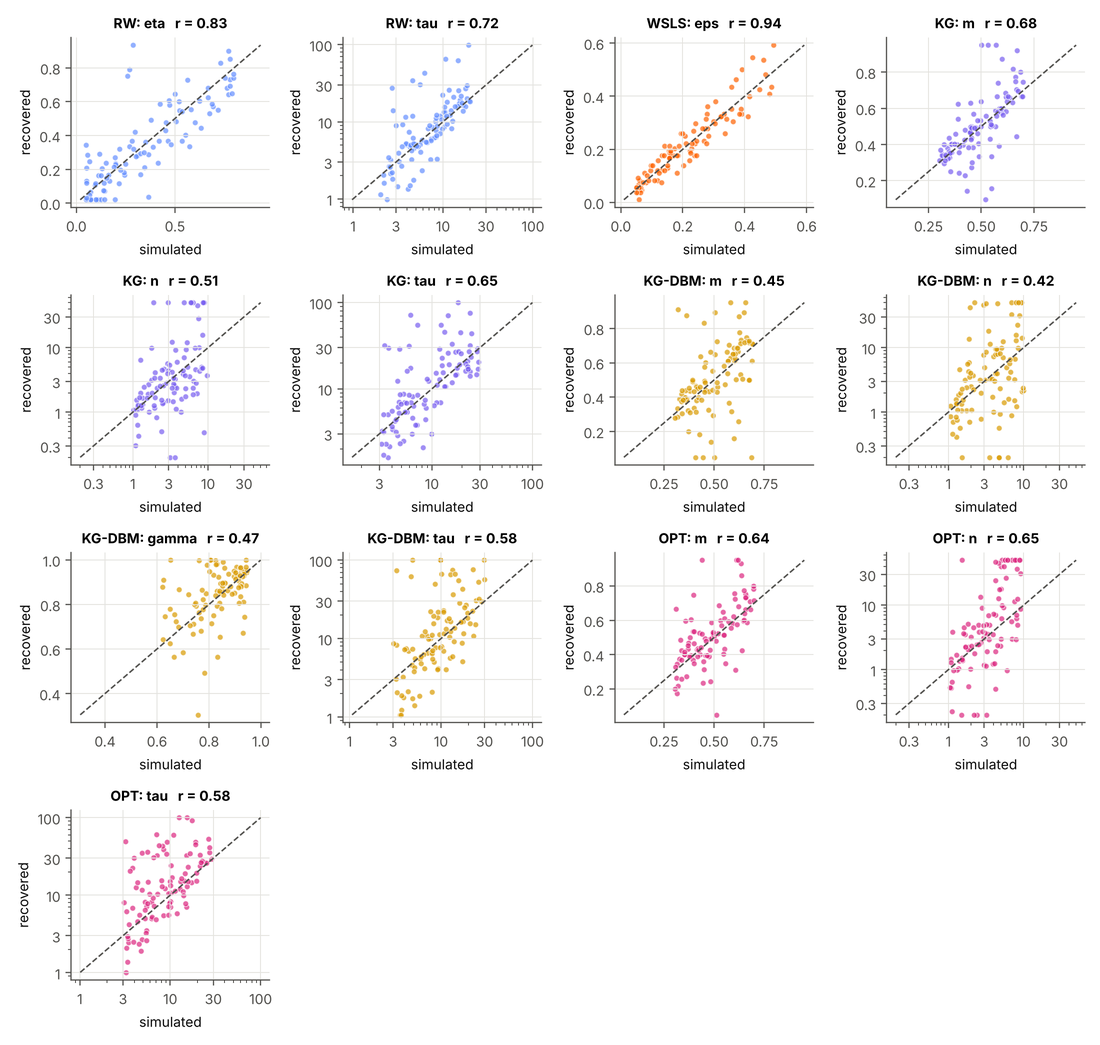

### 2.7 How many subjects do you need? (95% Wilson CI half-width for a recovery proportion p)

| observed p | N=20 | N=40 | N=60 | N=100 | N=200 | N=400 |
|---|---|---|---|---|---|---|
| p=0.5 | ±0.20 | ±0.15 | ±0.12 | ±0.10 | ±0.07 | ±0.05 |
| p=0.7 | ±0.19 | ±0.14 | ±0.11 | ±0.09 | ±0.06 | ±0.04 |
| p=0.9 | ±0.14 | ±0.10 | ±0.08 | ±0.06 | ±0.04 | ±0.03 |

Rule of thumb at p = 0.5: about 97 subjects per model for ±0.10 and 385 for ±0.05. The reference
run uses 100 per model (60 per cell in the design heat map), so differences smaller than about 0.1–0.15 should not be interpreted.

### 2.8 Take-aways

1. **Design guideline (§ 2.1).** To tell myopic (KG) from Bayes-optimal exploration, use games of about 12 or more trials and at
   least three arms; going from three to four arms adds little (0.82 vs 0.82
   decisive at T = 12), while the horizon matters a lot. At a fixed budget of 240 choices, accuracy is 0.32 with 2 arms × 4 trials
   but 0.93 with 4 arms × 15 trials, and the share of subjects with positive evidence (|ΔBIC| > 2) rises from
   0.02 to 0.88.
2. **Why short games fail.** With at most two choices left, KG is *exactly* optimal for any posteriors, and on the first trial both
   policies are indifferent. Only trials 2 … T−2 can carry information, a fraction (T−3)/T: none at T ≤ 3 (every subject is a tie),
   40% at T = 5, 85% at T = 20. The shared-prior T = 3 equality is therefore a consequence of symmetry, not a new result:
   with *unequal* posteriors and three choices left, the two policies differ (max gap difference 0.11 for 2 arms;
   unequal for 62% of random per-arm priors).
3. **Raw accuracy overstates the evidence at mid horizons.** On 2 arms, accuracy rises from 0.55 (T = 5) to
   0.84 (T = 20), but only 16% of subjects at T = 5 have positive evidence
   (4% strong). T = 20 and T = 30 are statistically indistinguishable.
4. **Zhang & Yu's regime works** (4 arms, 15 trials, 20 games, N = 100 per model): KG is recovered for 96%
   [95% CI 0.90–0.98] and OPT for 68%
   [0.58–0.76]. KG and OPT are rarely confused with each other there
   (KG→OPT 1%, OPT→KG 4%); OPT's remaining errors go mostly to RW
   (28%).
5. **On short 2-arm games, a delta-rule win is weak evidence.** At T = 10, RW wins for 37% of KG,
   39% of KG-DBM and 53% of OPT subjects; when RW wins, RW generated the data only
   42% of the time (an OPT win is right 80% of the time).
6. **Prior strength and decision noise are confounded** (error correlation 0.93 KG, 0.92
   KG-DBM, 0.94 OPT). Mixing horizons within a subject does not fix this (0.93 mixed vs
   0.93 / 0.95 fixed); longer games only make both more precise. Report n and τ
   jointly, or fix one of them.
7. **The forgetful KG-DBM is hard to identify on stationary bandits** (recovered 34%; γ r =
   0.47).
8. **Cross-validation and BIC disagree for 38% of subjects** (N = 100 per model): leave-one-game-out CV
   penalises complexity less, favouring KG-DBM more and RW less.

**Limitations.** All results come from simulated data. Simulation parameter ranges were set by hand, and the confusion matrices
depend on them. The tie threshold (|ΔBIC| < 0.1) is a practical choice. Fits are per subject (no hierarchical model). OPT
with a forgetful learner is not implemented (its beliefs are no longer counts).

**Next steps.** Fit real bandit data (e.g., Steyvers et al., 2009); test designs with forced-choice "free information" trials
(Wilson et al., 2014) against the n–τ trade-off; use adaptive design optimisation (Myung & Pitt, 2009; Cavagnaro et al., 2010);
add an I-POMDP module.

### References
- Acuna, D. E., & Schrater, P. (2010). Structure learning in human sequential decision-making. *PLoS Computational Biology*, 6(12), e1001003.
- Cavagnaro, D. R., Myung, J. I., Pitt, M. A., & Kujala, J. V. (2010). Adaptive design optimization: A mutual information-based approach to model discrimination in cognitive science. *Neural Computation*, 22(4), 887–905.
- Duff, M. O. (2002). *Optimal learning: Computational procedures for Bayes-adaptive Markov decision processes.* PhD thesis, UMass Amherst.
- Edwards, J., Fearnhead, P., & Glazebrook, K. (2016). On the identification and mitigation of weaknesses in the Knowledge Gradient policy for multi-armed bandits. arXiv:1607.05970.
- Frazier, P. I., Powell, W. B., & Dayanik, S. (2008). A knowledge-gradient policy for sequential information collection. *SIAM J. Control Optim.*, 47(5), 2410–2439.
- Guez, A., Silver, D., & Dayan, P. (2012). Efficient Bayes-adaptive reinforcement learning using sample-based search. *NeurIPS.*
- Kaelbling, L. P., Littman, M. L., & Cassandra, A. R. (1998). Planning and acting in partially observable stochastic domains. *Artificial Intelligence*, 101, 99–134.
- Kass, R. E., & Raftery, A. E. (1995). Bayes factors. *JASA*, 90(430), 773–795.
- Myung, J. I., & Pitt, M. A. (2009). Optimal experimental design for model discrimination. *Psychological Review*, 116(3), 499–518.
- Pineau, J., Gordon, G., & Thrun, S. (2003). Point-based value iteration: An anytime algorithm for POMDPs. *IJCAI.*
- Ryzhov, I. O., Powell, W. B., & Frazier, P. I. (2012). The knowledge gradient algorithm for a general class of online learning problems. *Operations Research*, 60(1), 180–195.
- Steyvers, M., Lee, M. D., & Wagenmakers, E.-J. (2009). A Bayesian analysis of human decision-making on bandit problems. *J. Mathematical Psychology*, 53(3), 168–179.
- Wilson, R. C., & Collins, A. G. E. (2019). Ten simple rules for the computational modeling of behavioral data. *eLife*, 8, e49547.
- Wilson, R. C., Geana, A., White, J. M., Ludvig, E. A., & Cohen, J. D. (2014). Humans use directed and random exploration to solve the explore–exploit dilemma. *J. Experimental Psychology: General*, 143(6), 2074–2081.
- Yu, A. J., & Cohen, J. D. (2009). Sequential effects: Superstition or rational behavior? *NeurIPS.*
- Zhang, S., & Yu, A. J. (2013). Forgetful Bayes and myopic planning: Human learning and decision-making in a bandit setting. *NeurIPS.*
- *Future work:* Gmytrasiewicz, P. J., & Doshi, P. (2005). A framework for sequential planning in multi-agent settings. *JAIR*, 24, 49–79 (I-POMDPs, not yet implemented).